Creating RawArray with float64 data, n_channels=8, n_times=75251
    Range : 0 ... 75250 =      0.000 ...   301.000 secs
Ready.
<Info | 8 non-empty values
 bads: []
 ch_names: Fz, C3, Cz, C4, Pz, PO7, Oz, PO8
 chs: 8 EEG
 custom_ref_applied: False
 dig: 11 items (3 Cardinal, 8 EEG)
 highpass: 0.0 Hz
 lowpass: 125.0 Hz
 meas_date: unspecified
 nchan: 8
 projs: []
 sfreq: 250.0 Hz
>
Remaining duration: 297.03 s
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).


c:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


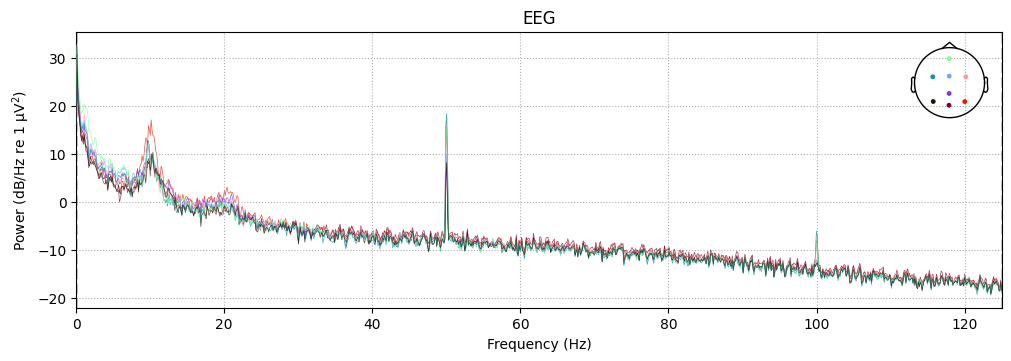

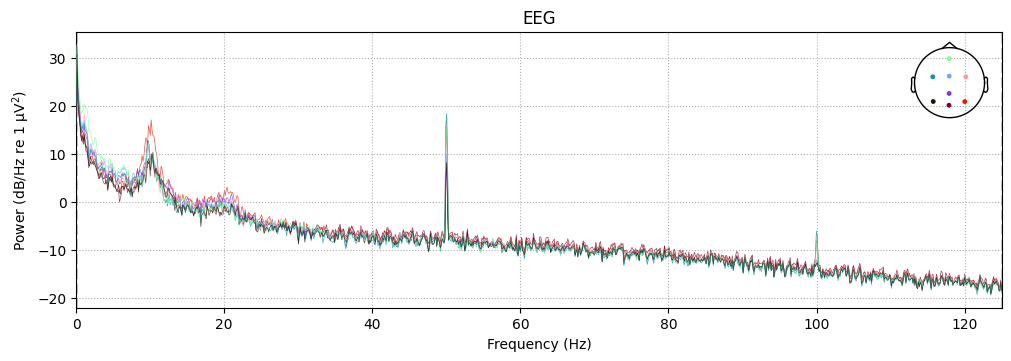

In [1]:
#we load the raw CSV into MNE and plot the PSD
#note: we dropp the first 3.97s because g.tec uses the beginning for gyroscope tuning
#the gyroscope is used to track head movement and filter out motion artifacts

import mne
import numpy as np

data = np.loadtxt(
    r"D:/Junk/New folder (2)/ya's stuff/ya's stuff/Downloads/Unicorn Recorder/Unicorn Recorder/UnicornRawDataRecorder_24_03_2026_11_36_120.csv",
    delimiter=',',
    skiprows=1
)

ch_names = ['Fz', 'C3', 'Cz', 'C4', 'Pz', 'PO7', 'Oz', 'PO8']
sfreq = 250.0
eeg_data = data[:, 0:8].T   

info = mne.create_info(ch_names=ch_names, sfreq=sfreq, ch_types=['eeg'] * 8)
raw = mne.io.RawArray(eeg_data * 1e-6, info)   # uV to Volts
raw.set_montage(mne.channels.make_standard_montage('standard_1020'))

raw.crop(tmin=3.97)

print(raw.info)
print(f"Remaining duration: {raw.times[-1]:.2f} s")

# PSD of the raw EEG 
raw.compute_psd().plot(picks='eeg')


Check the montage

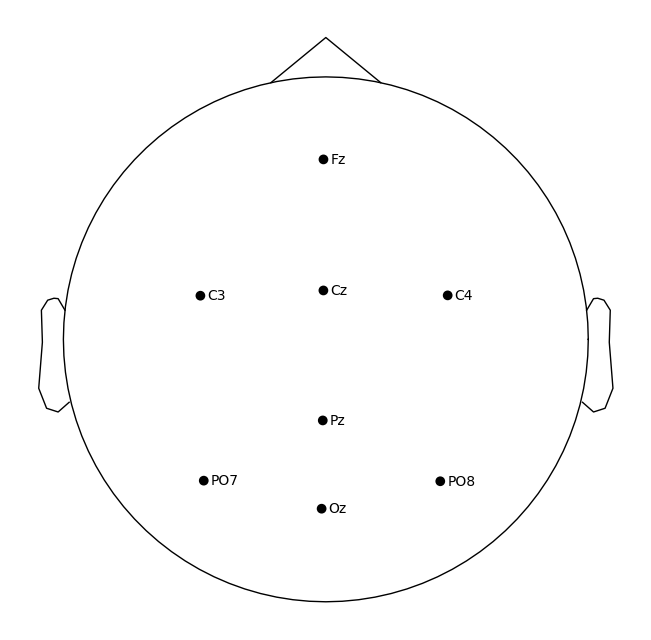

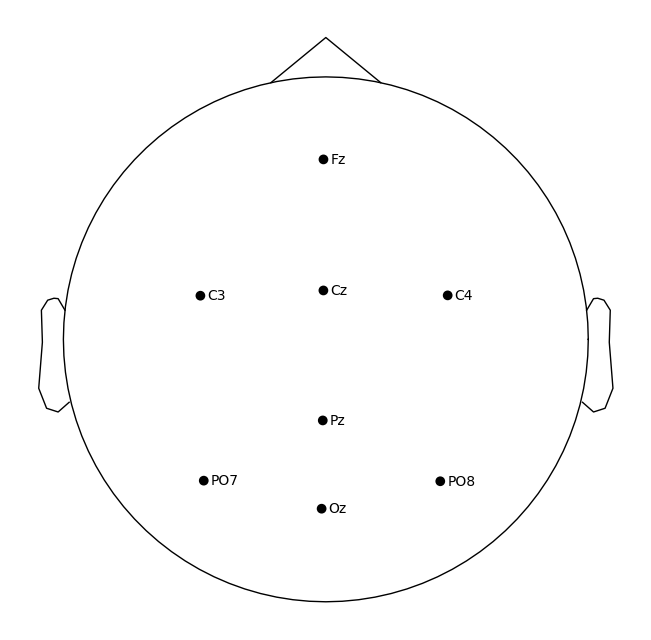

In [2]:
raw.plot_sensors(show_names=True)

We apply filters, then compare PSD before vs after 


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 825 samples (3.300 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge

c:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


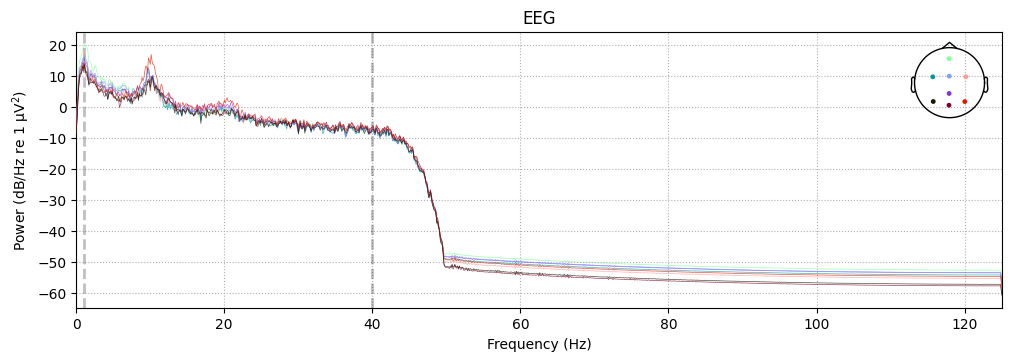

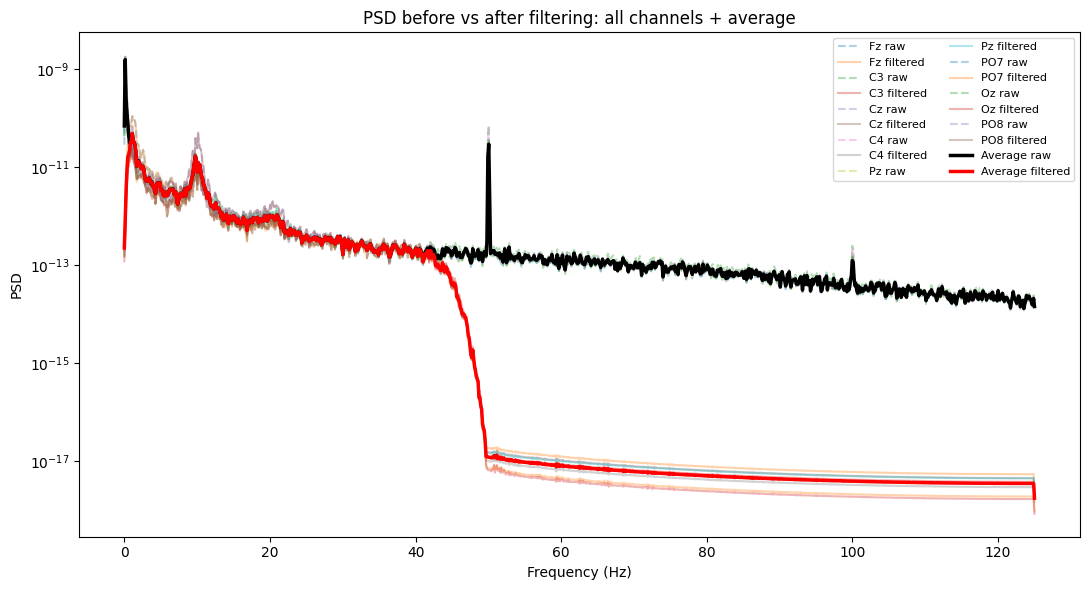

In [3]:
import matplotlib.pyplot as plt

raw_filtered = raw.copy().filter(
    l_freq=1.0,        # high-pass 
    h_freq=40.0,       # low-pass 
    fir_window='hamming',
    picks='eeg'
)
raw_filtered.notch_filter(freqs=50.0, picks='eeg')
raw_filtered.compute_psd().plot(picks='eeg') # plot PSD for filtered EEG

#first compare PSD before vs after filtering 
psds_raw, freqs_raw = raw.compute_psd().get_data(return_freqs=True)
psds_filt, freqs_filt = raw_filtered.compute_psd().get_data(return_freqs=True)

fig, ax = plt.subplots(figsize=(11, 6))

                                           #plot each channel
for i, ch in enumerate(raw.ch_names):
    ax.semilogy(freqs_raw, psds_raw[i], linestyle='--', alpha=0.35, label=f'{ch} raw')
    ax.semilogy(freqs_filt, psds_filt[i], alpha=0.35, label=f'{ch} filtered')

                                      #plot channel-average PSD 
ax.semilogy(
    freqs_raw,
    psds_raw.mean(axis=0),
    color='black',
    linewidth=2.5,
    label='Average raw'
)
ax.semilogy(
    freqs_filt,
    psds_filt.mean(axis=0),
    color='red',
    linewidth=2.5,
    label='Average filtered'
)

ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('PSD')
ax.set_title('PSD before vs after filtering: all channels + average')
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()


Inspect the filtered EEG for bad channels

Using matplotlib as 2D backend.


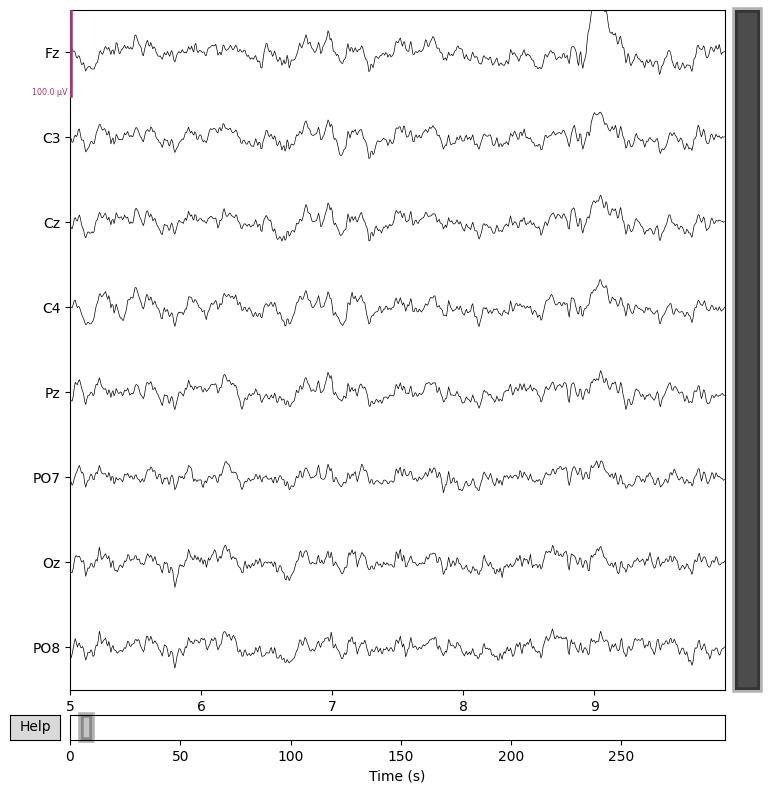

Bad channels: []


In [4]:
import matplotlib as qt

raw_filtered.plot(
    start=5,
    duration=5,
    n_channels=8,
    scalings=dict(eeg=50e-6),
    remove_dc=True,
    title='Filtered EEG: visual bad-channel check',
    block=True
)

print("Bad channels:", raw_filtered.info['bads'])


#if PO7 looks bad, mark it like this
#raw_filtered.info['bads'] = ['PO7']

#then interpolate the bad channel from neighboring electrodes
#raw_filtered.interpolate_bads(reset_bads=False)


Next, for the continuous EEG: 
1. Cuts it into 5 experimental blocks
2. Splits each block into small time windows (epochs)
3. Assigns a label to each window

In [5]:
#crop blocks, epoch, and label
from mne.epochs import make_fixed_length_epochs

task_duration = 300.0
t_offset = max(0.0, raw_filtered.times[-1] - task_duration) #if recording is 304s, then t_offset = 4s, so we keep the last 300s for epoching

print("Raw max time :", f"{raw_filtered.times[-1]:.3f} s")
print(f"t_offset     : {t_offset:.3f} s")

BLOCKS = {
    'eyes_open_1':        (t_offset,        t_offset + 60),
    'eyes_closed_1':      (t_offset + 60,   t_offset + 120),
    'mental_arithmetic':  (t_offset + 120,  t_offset + 180),
    'eyes_open_2':        (t_offset + 180,  t_offset + 240),
    'eyes_closed_2':      (t_offset + 240,  t_offset + 300),
}

all_epochs, all_labels = [], []

for block_name, (t0, t1) in BLOCKS.items():
    t1_clamped = min(t1, raw_filtered.times[-1])
    raw_block = raw_filtered.copy().crop(tmin=t0, tmax=t1_clamped)
    ep = make_fixed_length_epochs(
        raw_block,
        duration=2.0,
        overlap=1.0,          #like this 0–2, 1–3, 2–4, ...
        preload=True
    )
    all_epochs.append(ep)
    all_labels.extend([block_name] * len(ep))
    print(f'{block_name:20s}: {len(ep)} epochs')

epochs_all = mne.concatenate_epochs(all_epochs)
labels = np.array(all_labels)

print(f'Total epoch: {len(epochs_all)}')
print(f'Data shape: {epochs_all.get_data().shape}')


Raw max time : 297.032 s
t_offset     : 0.000 s
Not setting metadata
59 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 59 events and 500 original time points ...
0 bad epochs dropped
eyes_open_1         : 59 epochs
Not setting metadata
59 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 59 events and 500 original time points ...
0 bad epochs dropped
eyes_closed_1       : 59 epochs
Not setting metadata
59 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 59 events and 500 original time points ...
0 bad epochs dropped
mental_arithmetic   : 59 epochs
Not setting metadata
59 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 59 events and 500 original time points ...
0 bad epochs dropped
eyes_open_2         : 59 epochs
Not sett

Reject bad epochs and keep labels in sync

In [6]:
#reject epochs with peak-to-peak EEG amplitude > 100 uV

labels_before = labels.copy()

epochs_all.drop_bad(reject=dict(eeg=100e-6))

kept_mask = np.array([len(log) == 0 for log in epochs_all.drop_log])
labels = labels_before[kept_mask]

print(f'Epochs after rejection : {len(epochs_all)}')
print('Counts per block       :')
for name in BLOCKS:
    print(f'  {name:20s}: {(labels == name).sum()}')


    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['PO8']
    Rejecting  epoch based on EEG : ['PO8']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz', 'C3', 'Cz']
    Rejecting  epoch based on EEG : ['Fz', 'C3', 'Cz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based o

In [7]:
print(f'Epochs after rejection : {len(epochs_all)}')
print('Counts per block       :')
for name in BLOCKS:
    print(f'  {name:20s}: {(labels == name).sum()}')

Epochs after rejection : 250
Counts per block       :
  eyes_open_1         : 46
  eyes_closed_1       : 55
  mental_arithmetic   : 55
  eyes_open_2         : 48
  eyes_closed_2       : 46


Fit ICA to the filtered EEG

In [8]:
from mne.preprocessing import ICA

ica = ICA(
    n_components=0.99,     # keep enough components to explain 99% variance
    method='fastica',
    random_state=42,
    max_iter=800
)

ica.fit(raw_filtered, picks='eeg')
print('ICA fitted.')



Fitting ICA to data using 8 channels (please be patient, this may take a while)
Selecting by explained variance: 7 components
Fitting ICA took 0.4s.
ICA fitted.


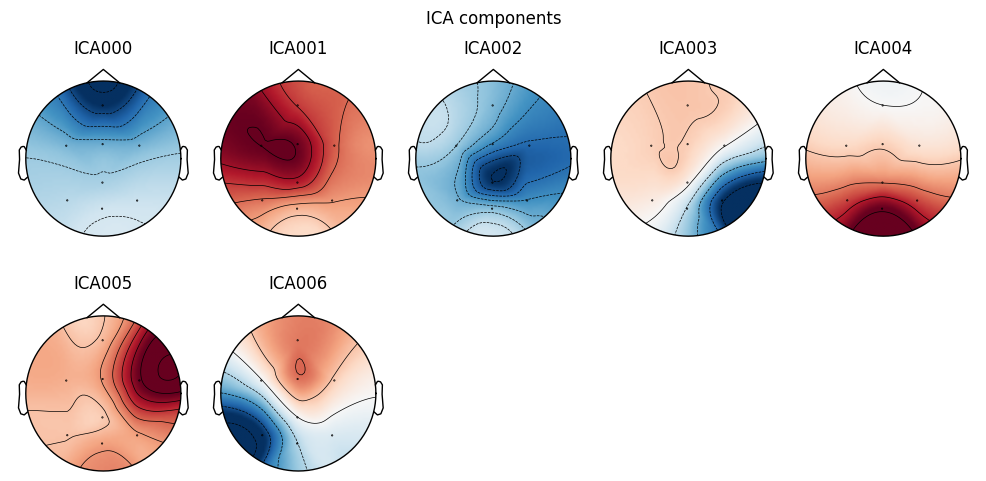

Creating RawArray with float64 data, n_channels=7, n_times=74259
    Range : 992 ... 75250 =      3.968 ...   301.000 secs
Ready.


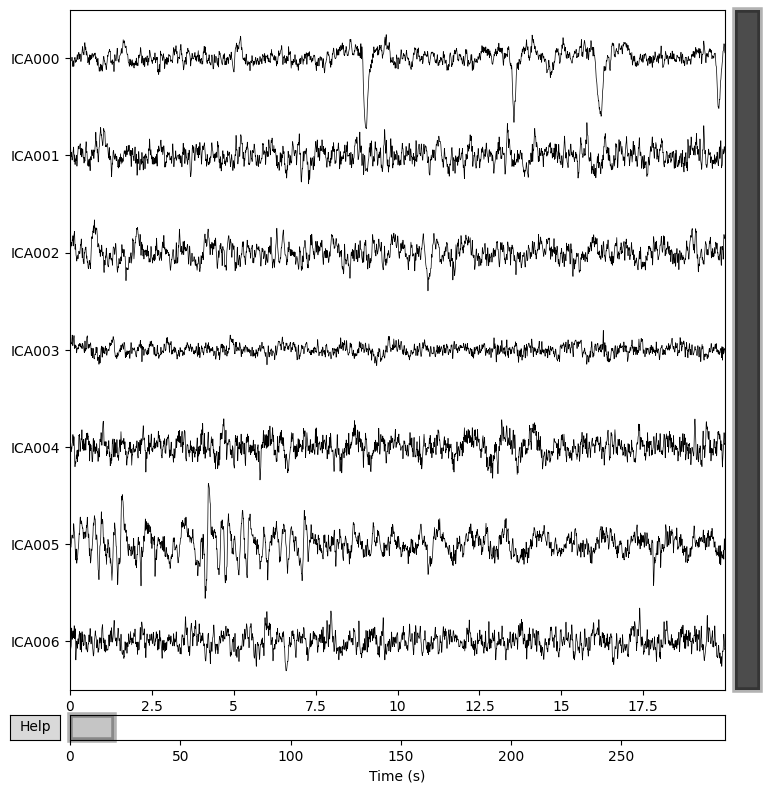

    Using multitaper spectrum estimation with 7 DPSS windows
Not setting metadata
148 matching events found
No baseline correction applied
0 projection items activated


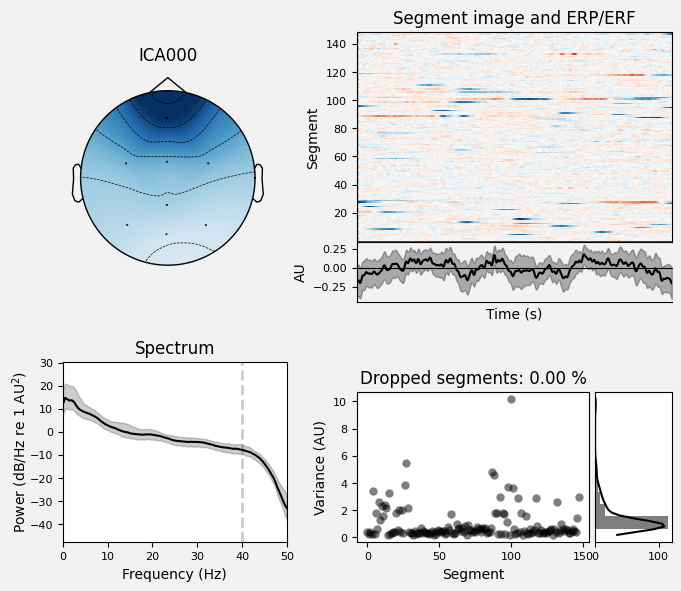

[<Figure size 700x600 with 6 Axes>]

In [9]:
#plot ICA component topographies
ica.plot_components()
 
#plot the time course of every component
#look for the component with sharp irregular spikes = blinks
ica.plot_sources(raw_filtered)
 
# Detailed view of a specific component
ica.plot_properties(raw_filtered, picks=[0])
# Shows: topography + time course + PSD + epoch image


Exclude the blink component and apply ICA

Applying ICA to Raw instance
    Transforming to ICA space (7 components)
    Zeroing out 2 ICA components
    Projecting back using 8 PCA components


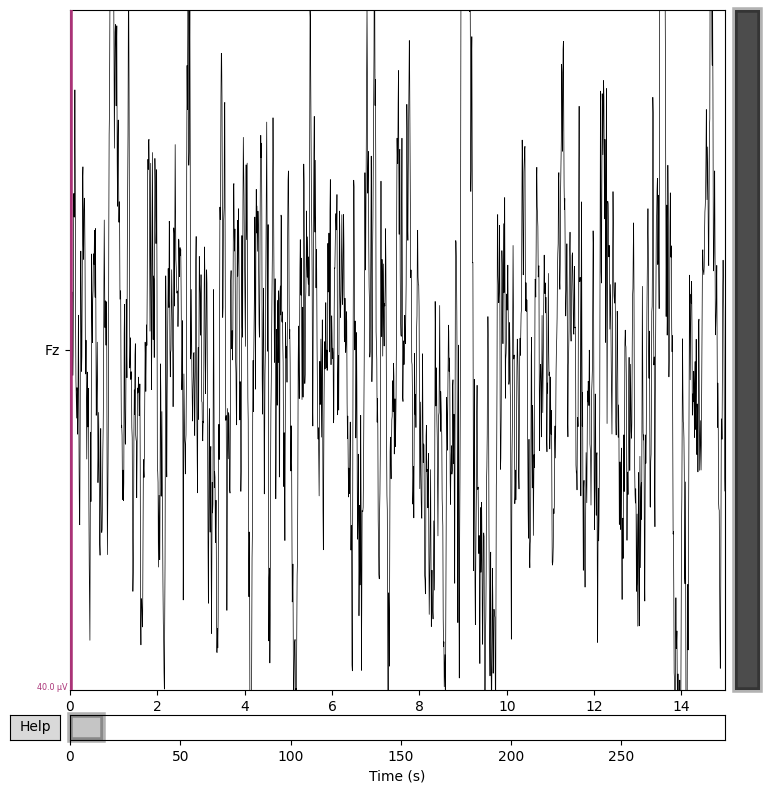

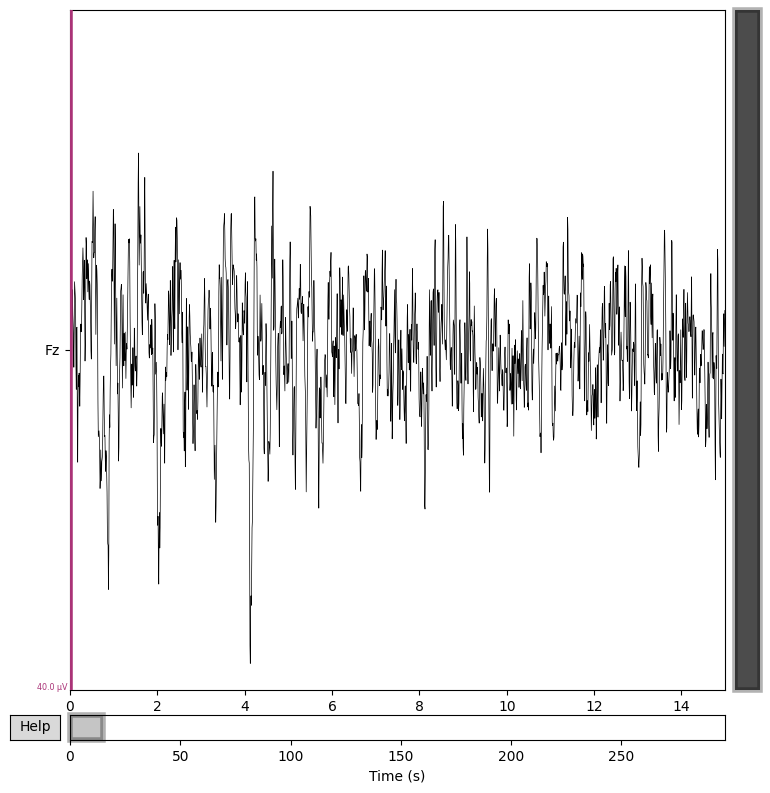

Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


c:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)
c:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


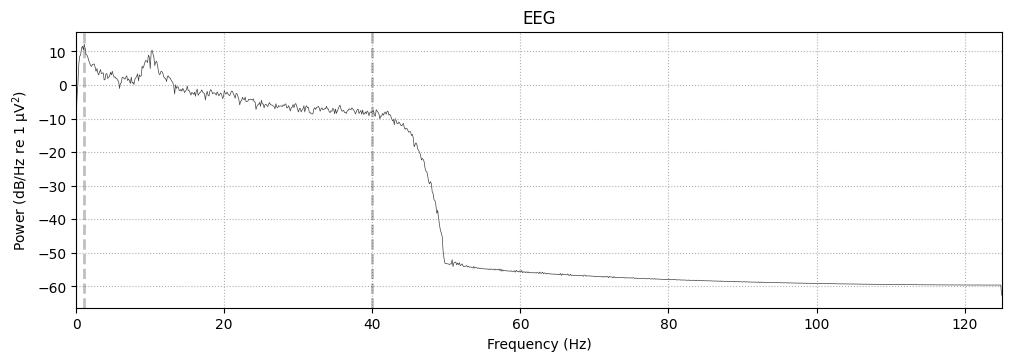

In [10]:

ica.exclude = [0,1]
 
raw_clean = raw_filtered.copy()
ica.apply(raw_clean)
 
 
#Fz before and after
raw_filtered.plot(picks=['Fz'], duration=15,
                  title='Fz  BEFORE ICA')
raw_clean.plot(picks=['Fz'],    duration=15,
               title='Fz  AFTER ICA')
 
#alpha at Oz must be unchanged
raw_filtered.compute_psd(picks=['Oz']).plot()
raw_clean.compute_psd(picks=['Oz']).plot()


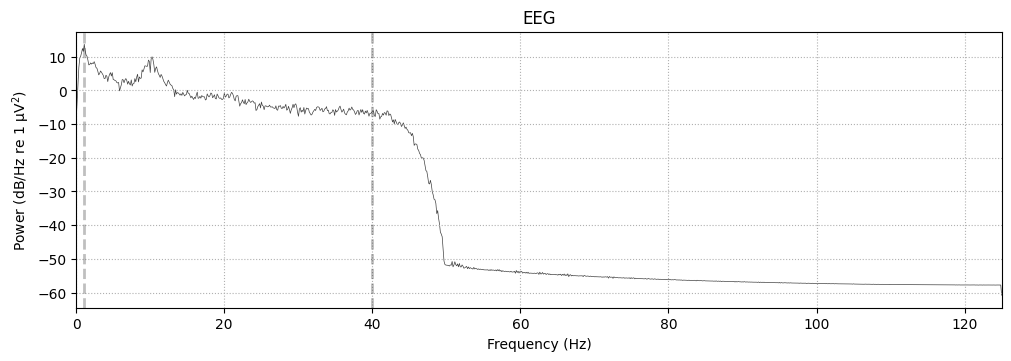

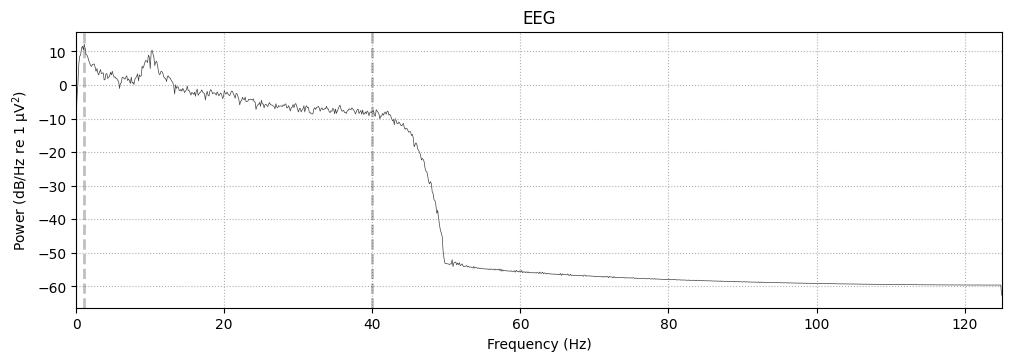

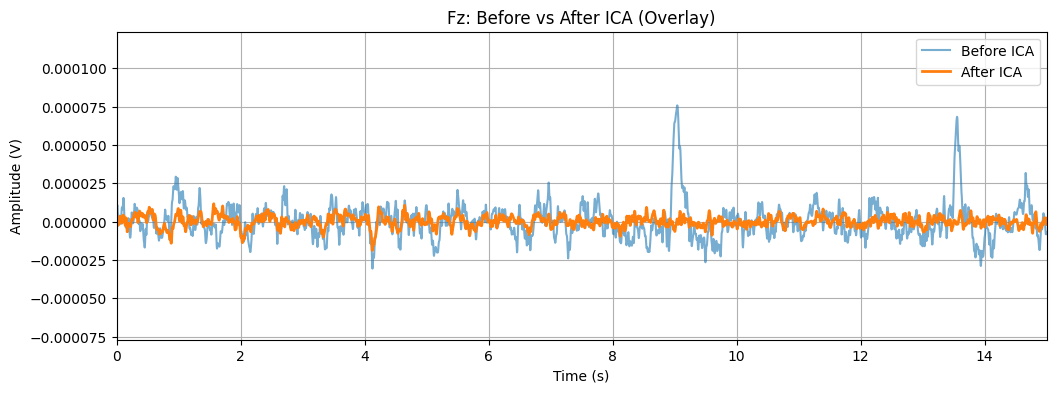

In [11]:
import matplotlib.pyplot as plt

# Extract Fz data
filt_data = raw_filtered.get_data(picks=['Fz'])[0]
clean_data = raw_clean.get_data(picks=['Fz'])[0]
times = raw_filtered.times

# Plot overlay
plt.figure(figsize=(12, 4))
plt.plot(times, filt_data, label='Before ICA', alpha=0.6)
plt.plot(times, clean_data, label='After ICA', linewidth=2)

plt.title('Fz: Before vs After ICA (Overlay)')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude (V)')
plt.legend()
plt.grid()

plt.xlim(0, 15)  # zoom into first 15 seconds
plt.show()

Re-epoch the clean recording and save all outputs

In [12]:
from mne.epochs import make_fixed_length_epochs
 
#re-epoch from the ICA-cleaned signal
all_epochs_clean, all_labels_clean = [], []
 
for block_name, (t0, t1) in BLOCKS.items():
    t1_clamped = min(t1, raw_filtered.times[-1])
    raw_block = raw_filtered.copy().crop(tmin=t0, tmax=t1_clamped)
    ep = make_fixed_length_epochs(raw_block, duration=2.0,
                                   overlap=1.0, preload=True)
    ep.drop_bad(reject=dict(eeg=100e-6))
    all_epochs_clean.append(ep)
    all_labels_clean.extend([block_name] * len(ep))
 
epochs_final = mne.concatenate_epochs(all_epochs_clean)
labels_final = np.array(all_labels_clean)
 
#save 
raw_clean.save('S01_clean_raw.fif', overwrite=True)
epochs_final.save('S01_clean_epochs-epo.fif', overwrite=True)
np.save('S01_labels.npy', labels_final)
 
print(f'Final shape: {epochs_final.get_data().shape}')
print(f'Labels:      {np.unique(labels_final, return_counts=True)}')


Not setting metadata
59 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 59 events and 500 original time points ...
0 bad epochs dropped
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
13 bad epochs dropped
Not setting metadata
59 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 59 events and 500 original time points ...
0 bad epochs dropped
    Rejecti

In [13]:
print(f'Final epochs : {len(epochs_final)}')
print('Counts per block:')
for name in BLOCKS:
    print(f'  {name:20s}: {(labels_final == name).sum()}')


Final epochs : 250
Counts per block:
  eyes_open_1         : 46
  eyes_closed_1       : 55
  mental_arithmetic   : 55
  eyes_open_2         : 48
  eyes_closed_2       : 46


Load, inspect, and visualize the saved outputs

Opening raw data file S01_clean_raw.fif...
    Range : 992 ... 75250 =      3.968 ...   301.000 secs
Ready.
Reading 0 ... 74258  =      0.000 ...   297.032 secs...
Reading d:\Junk\New folder (2)\ya's stuff\ya's stuff\Downloads\Unicorn Recorder\Unicorn Recorder\S01_clean_epochs-epo.fif ...
    Found the data of interest:
        t =       0.00 ...    1996.00 ms
        0 CTF compensation matrices available
Not setting metadata
250 matching events found
No baseline correction applied
0 projection items activated
  eyes_closed_1       : 55
  eyes_closed_2       : 46
  eyes_open_1         : 46
  eyes_open_2         : 48
  mental_arithmetic   : 55


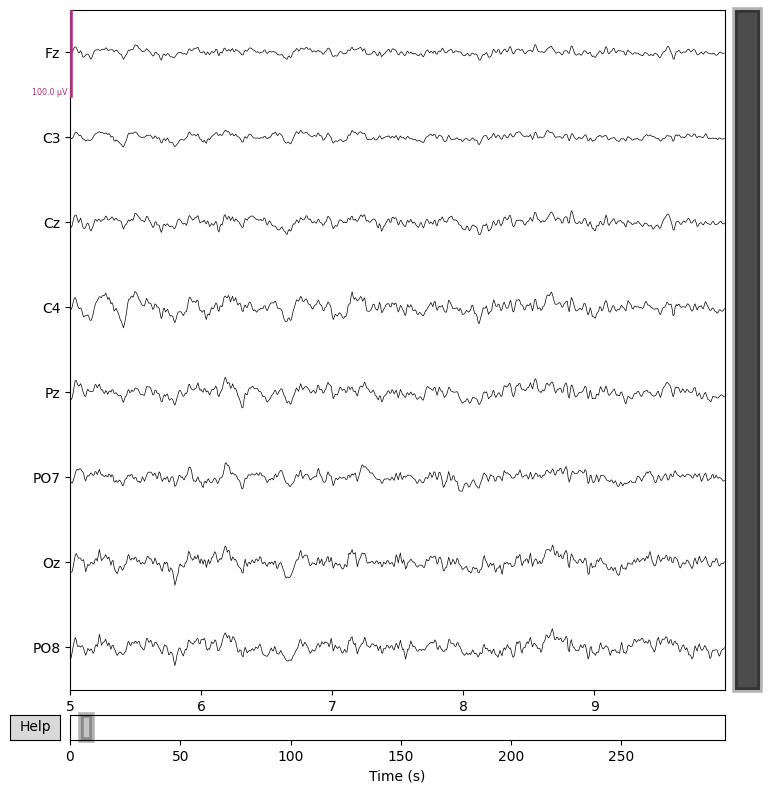

Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).


c:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


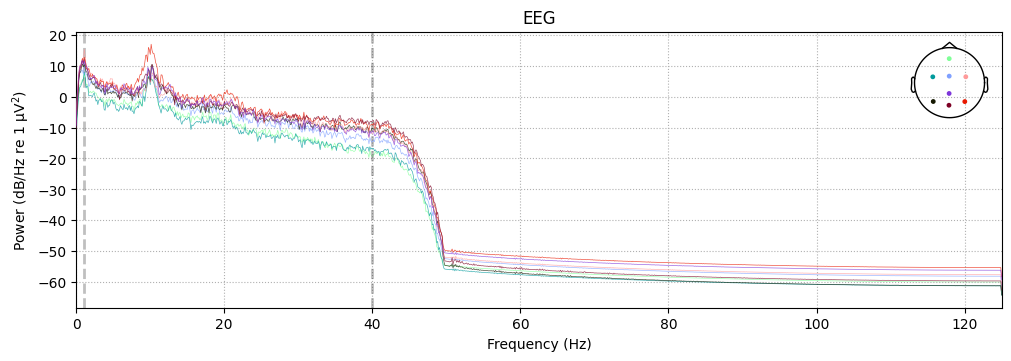

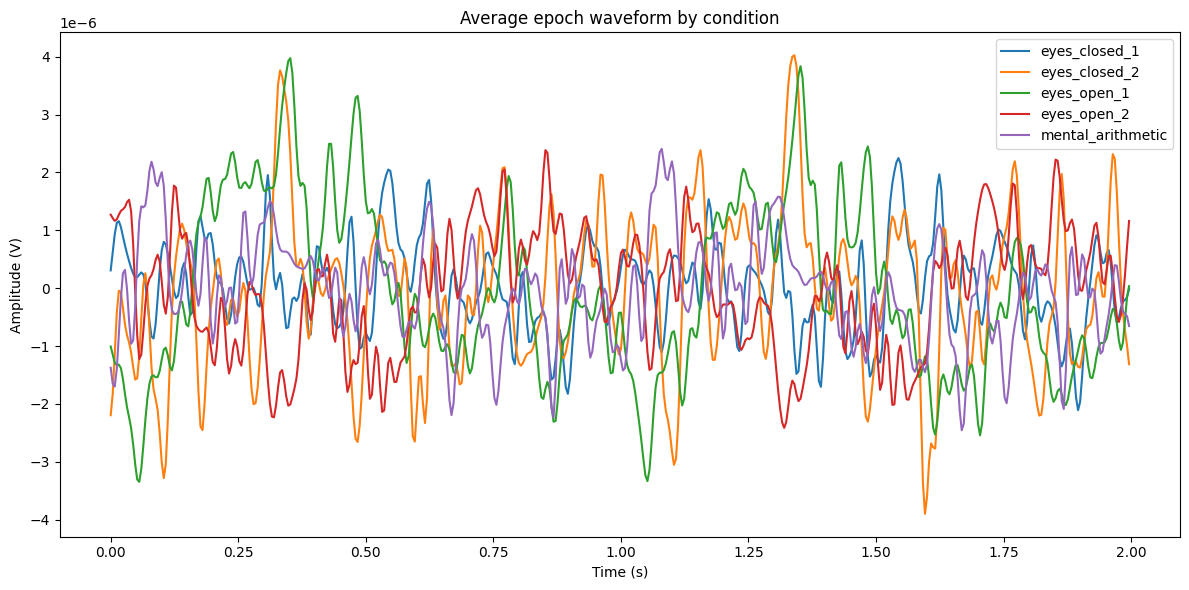

    Using multitaper spectrum estimation with 7 DPSS windows
    Using multitaper spectrum estimation with 7 DPSS windows
    Using multitaper spectrum estimation with 7 DPSS windows
    Using multitaper spectrum estimation with 7 DPSS windows
    Using multitaper spectrum estimation with 7 DPSS windows


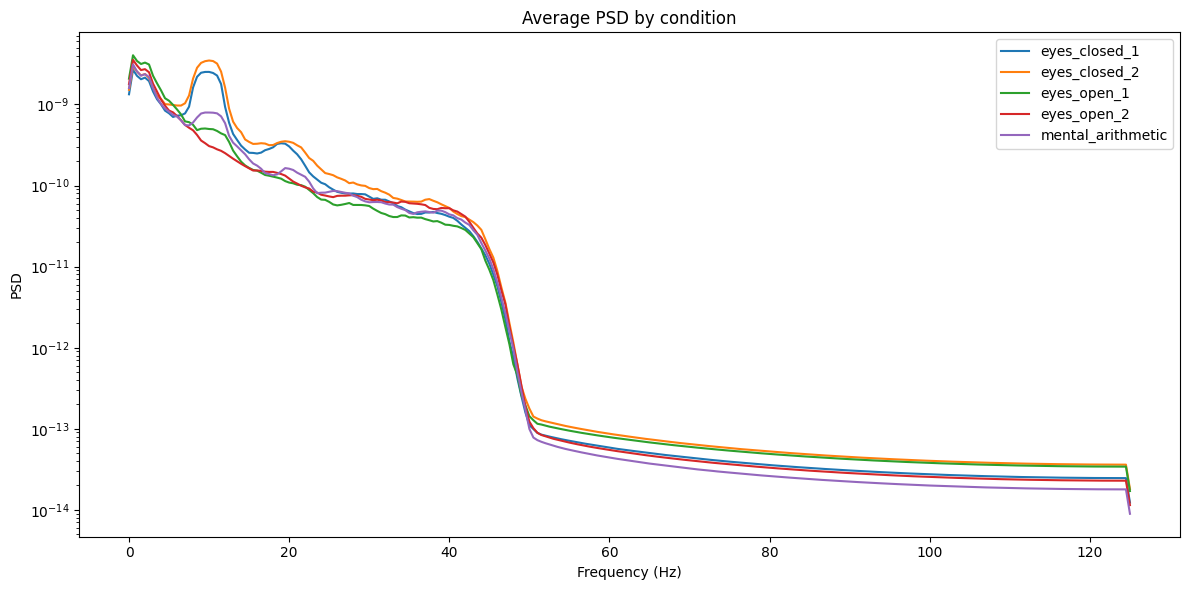

In [14]:

import mne
import numpy as np
import matplotlib.pyplot as plt

raw_saved = mne.io.read_raw_fif('S01_clean_raw.fif', preload=True)
epochs_saved = mne.read_epochs('S01_clean_epochs-epo.fif', preload=True)
labels_saved = np.load('S01_labels.npy', allow_pickle=True)


unique_labels, counts = np.unique(labels_saved, return_counts=True)
for name, count in zip(unique_labels, counts):
    print(f'  {name:20s}: {count}')

# plot 1: cleaned raw EEG browser
raw_saved.plot(
    start=5,
    duration=5,
    n_channels=8,
    scalings=dict(eeg=50e-6),
    remove_dc=True,
    title='Saved cleaned EEG'
)

# plot 2: PSD of the cleaned recording
raw_saved.compute_psd().plot(picks='eeg')

# plot 3: average signal across epochs for each condition
fig, ax = plt.subplots(figsize=(12, 6))

for label in unique_labels:
    idx = np.where(labels_saved == label)[0]
    data = epochs_saved.get_data()[idx]             # (n_epochs, n_channels, n_times)
    mean_wave = data.mean(axis=(0, 1))              # average across epochs and channels
    times = epochs_saved.times
    ax.plot(times, mean_wave, label=label)

ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude (V)')
ax.set_title('Average epoch waveform by condition')
ax.legend()
plt.tight_layout()
plt.show()

# plot 4: compare average PSD by condition
fig, ax = plt.subplots(figsize=(12, 6))

for label in unique_labels:
    idx = np.where(labels_saved == label)[0]
    psd = epochs_saved[idx].compute_psd()
    psds, freqs = psd.get_data(return_freqs=True)
    mean_psd = psds.mean(axis=(0, 1))               # average across epochs and channels
    ax.semilogy(freqs, mean_psd, label=label)

ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('PSD')
ax.set_title('Average PSD by condition')
ax.legend()
plt.tight_layout()
plt.show()
